# 🐀 MVP-2 — Agent Body (Policy + Interaction)
## 🎯 Goal of MVP-2

Creating an agent that:

- knows its state
- can choose actions
- can interact with the environment
- but does not plan yet

_This is our baseline organism._

In [13]:
import numpy as np
import matplotlib.pyplot as plt

### Agent Class

In [3]:
import random

class Agent:
    def __init__(self, action_space=4, epsilon=0.2):
        """
        action_space: number of actions (up, down, left, right)
        epsilon: exploration probability
        """
        self.action_space = action_space
        self.epsilon = epsilon

    def select_action(self, state):
        """
        Stateless for now.
        Later this will depend on value estimates / imagination.
        """
        if random.random() < self.epsilon:
            return random.randint(0, self.action_space - 1)
        else:
            # placeholder for greedy action (same as random for now)
            return random.randint(0, self.action_space - 1)


# greedy = random for now as this MVP is about structure not intelligence

In [6]:
def render(
    env,
    imagined_paths=None,
    chosen_path=None,
    title="Maze Environment"
):
    """
    imagined_paths: list of lists of (x, y) tuples
    chosen_path: list of (x, y) tuples
    """

    fig, ax = plt.subplots(figsize=(5, 5))

    # --- Draw maze background ---
    for x in range(env.height):
        for y in range(env.width):
            if env.maze[x, y] == 1:      # wall
                ax.add_patch(plt.Rectangle((y, x), 1, 1, color="black"))
            else:                        # free space
                ax.add_patch(plt.Rectangle((y, x), 1, 1, color="white"))

    # --- Draw start & goal ---
    sx, sy = env.start_pos
    gx, gy = env.goal_pos

    ax.text(sy + 0.5, sx + 0.5, "S", ha="center", va="center", fontsize=12)
    ax.text(gy + 0.5, gx + 0.5, "G", ha="center", va="center", fontsize=12)

    # --- Draw imagined trajectories (future use) ---
    if imagined_paths is not None:
        for path in imagined_paths:
            xs = [y + 0.5 for x, y in path]
            ys = [x + 0.5 for x, y in path]
            ax.plot(xs, ys, linestyle="dotted", alpha=0.4, color="blue")

    # --- Draw chosen path (future use) ---
    if chosen_path is not None:
        xs = [y + 0.5 for x, y in chosen_path]
        ys = [x + 0.5 for x, y in chosen_path]
        ax.plot(xs, ys, linewidth=2.5, color="red")

    # --- Draw agent ---
    ax.scatter(
        env.agent_pos[1] + 0.5,
        env.agent_pos[0] + 0.5,
        s=200,
        color="orange",
        zorder=5
    )

    # --- Formatting ---
    ax.set_xlim(0, env.width)
    ax.set_ylim(env.height, 0)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title)
    ax.set_aspect("equal")

    plt.show()


In [7]:
class MazeEnv:
    def __init__(self, maze):
        self.maze = maze
        self.height, self.width = maze.shape
        self.start_pos = tuple(np.argwhere(maze == 2)[0])
        self.goal_pos = tuple(np.argwhere(maze == 3)[0])
        self.reset()

    def reset(self):
        self.agent_pos = self.start_pos
        return self.agent_pos

    def step(self, action):
        moves = {
            0: (-1, 0),  # up
            1: (1, 0),   # down
            2: (0, -1),  # left
            3: (0, 1)    # right
        }

        dx, dy = moves[action]
        x, y = self.agent_pos
        nx, ny = x + dx, y + dy

        # Check boundaries and walls
        if 0 <= nx < self.height and 0 <= ny < self.width:
            if self.maze[nx, ny] != 1:
                self.agent_pos = (nx, ny)

        reward = 1 if self.agent_pos == self.goal_pos else 0
        done = self.agent_pos == self.goal_pos

        return self.agent_pos, reward, done


In [8]:
def run_agent_episode(env, agent, max_steps=50, delay=0.3):
    state = env.reset()
    render(env, title="Agent Acting (No Planning)")

    for step in range(max_steps):
        action = agent.select_action(state)
        next_state, reward, done = env.step(action)

        render(env, title=f"Step {step+1}")
        state = next_state

        if done:
            print(f"🎯 Reached goal in {step+1} steps")
            return

    print("❌ Episode ended without reaching goal")


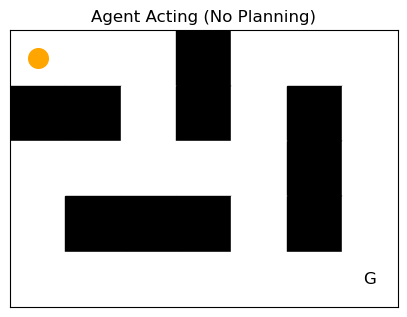

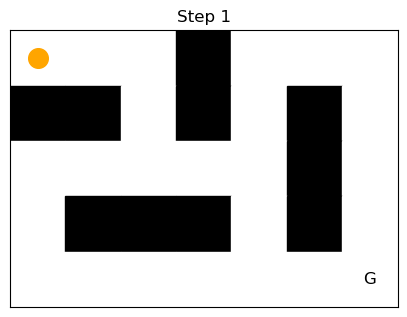

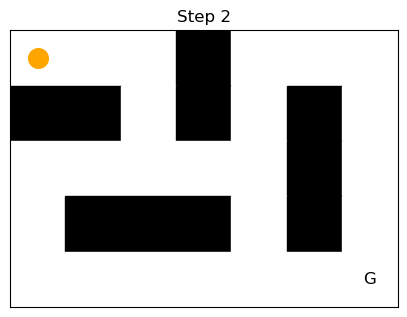

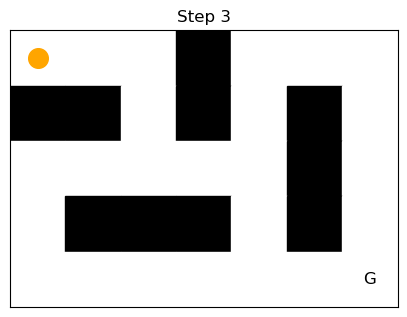

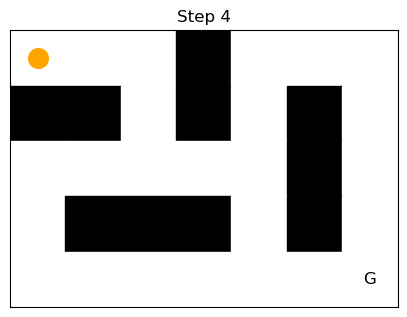

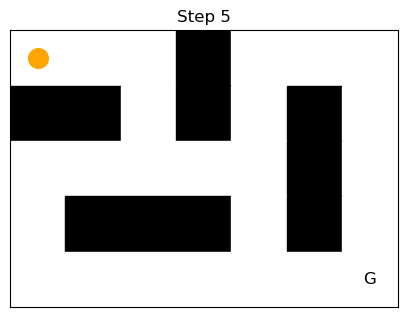

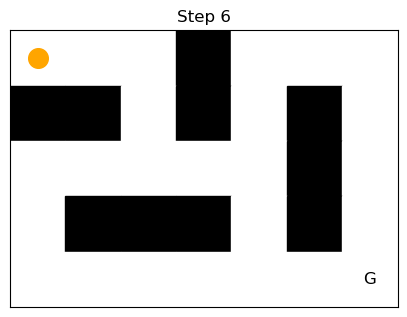

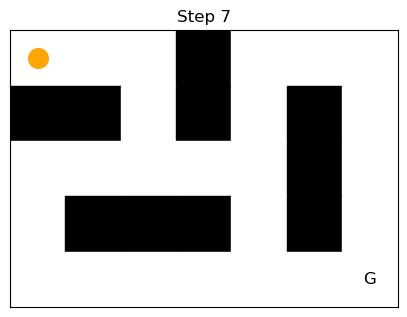

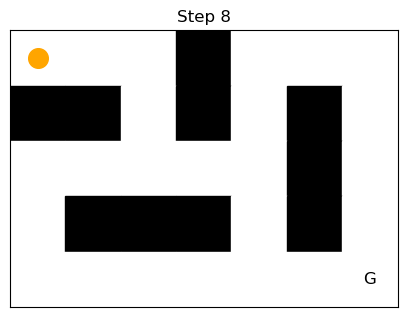

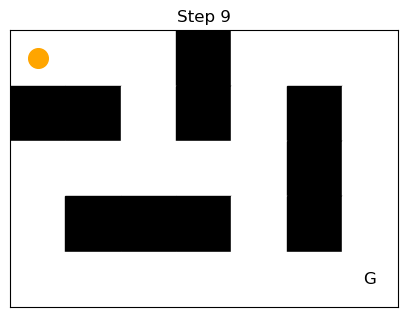

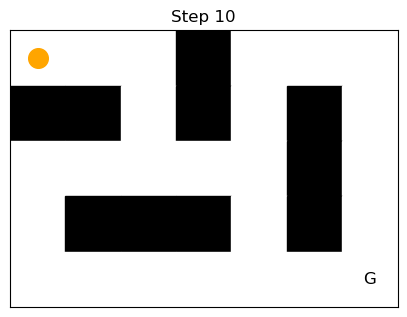

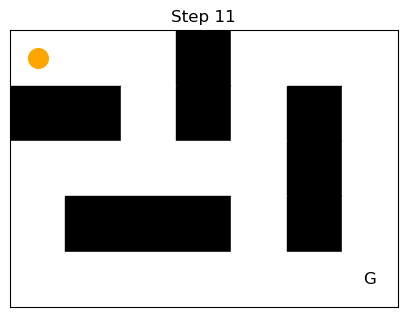

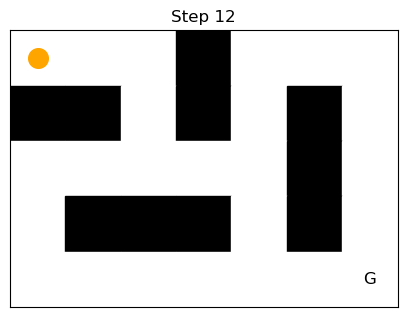

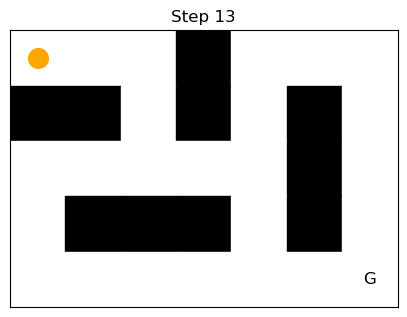

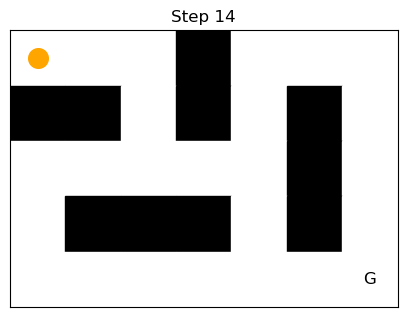

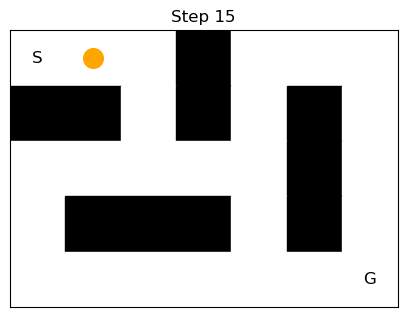

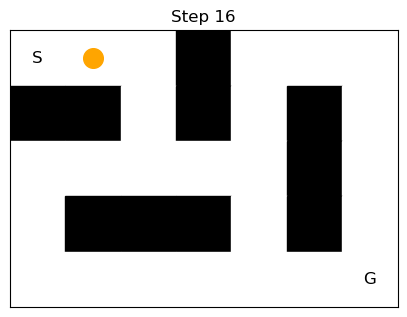

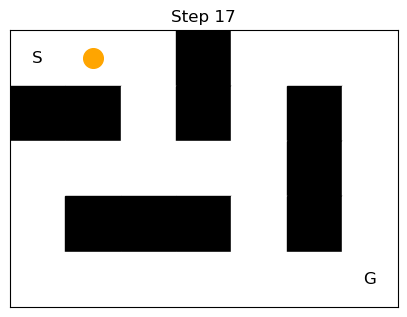

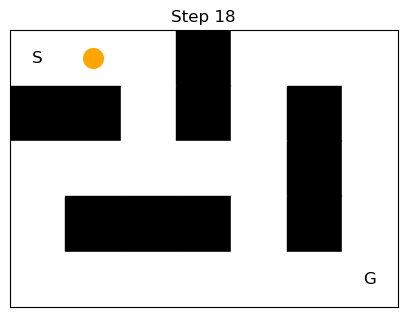

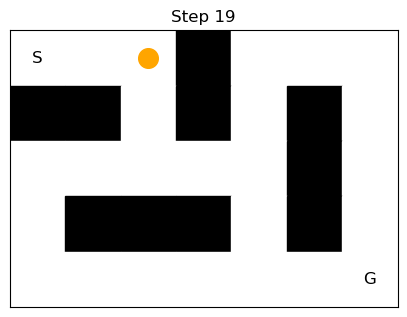

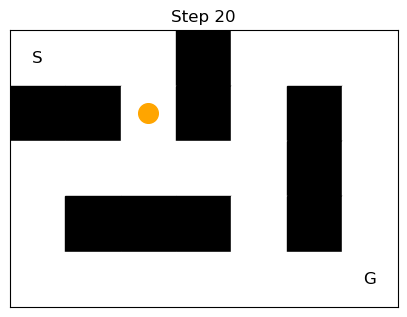

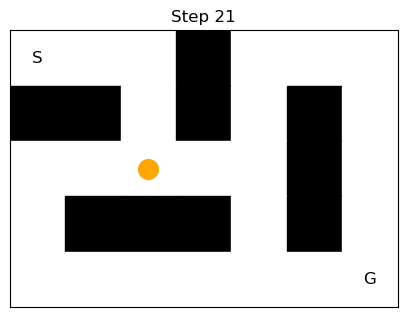

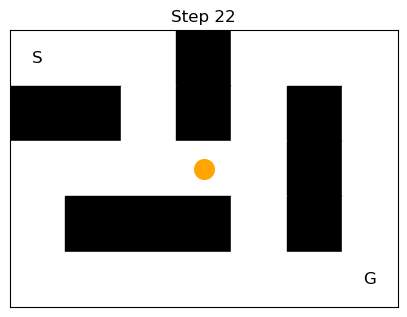

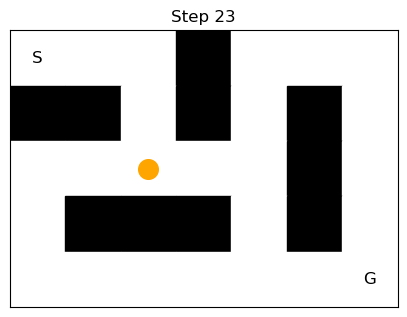

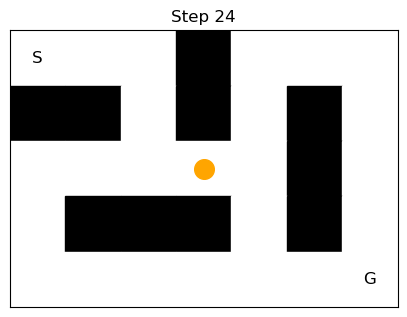

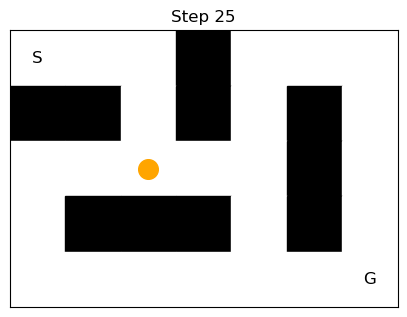

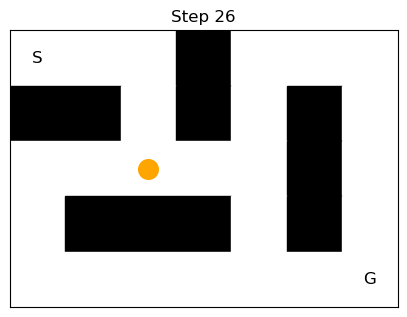

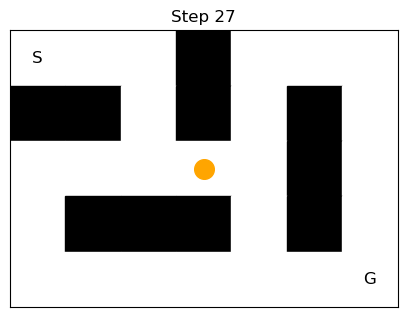

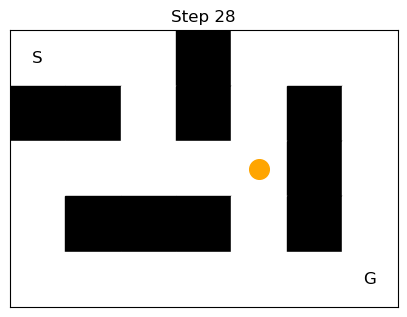

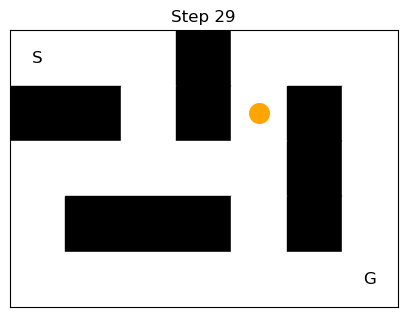

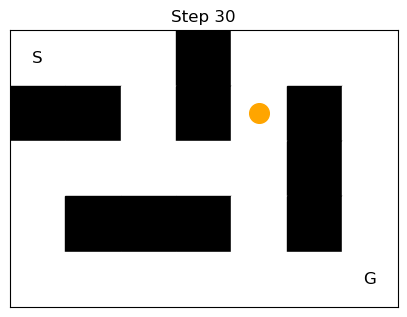

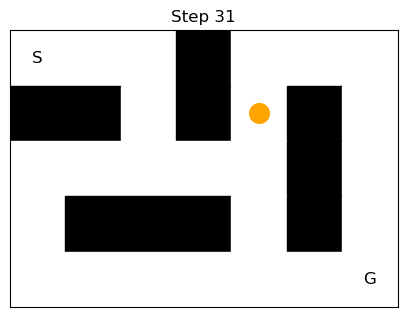

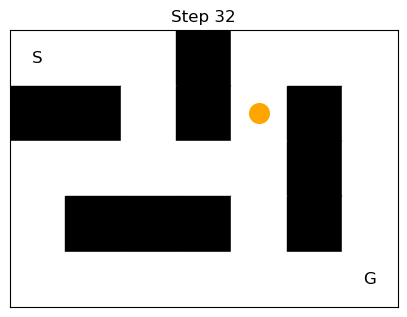

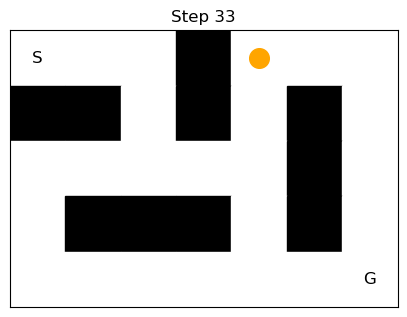

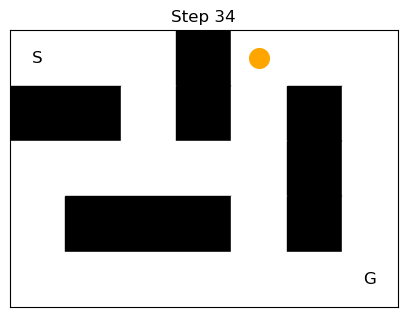

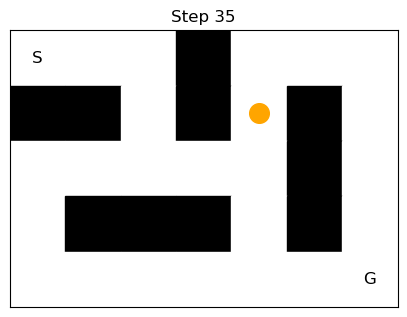

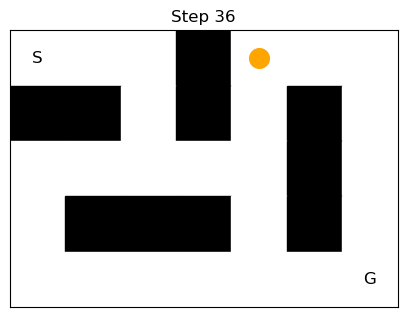

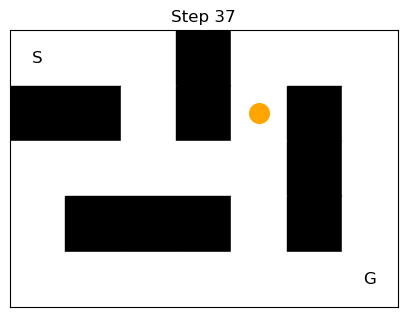

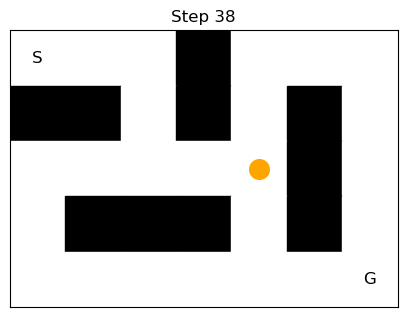

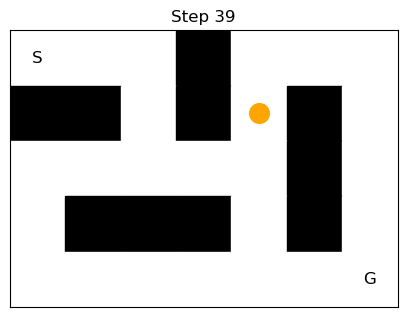

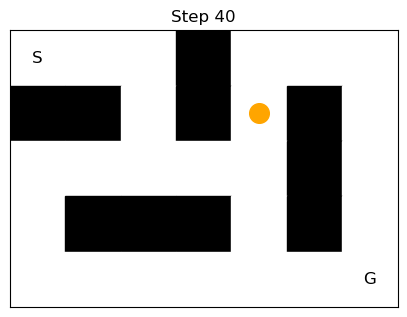

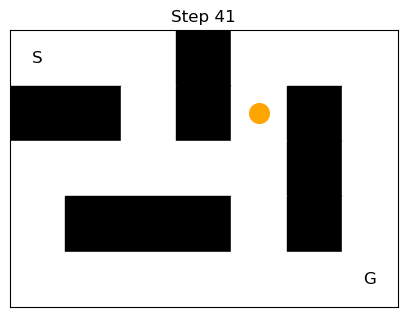

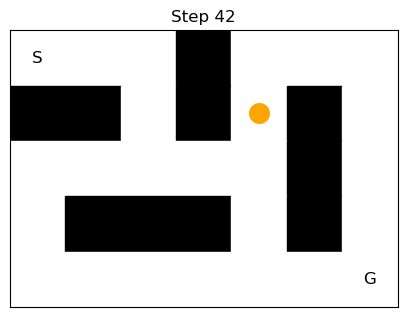

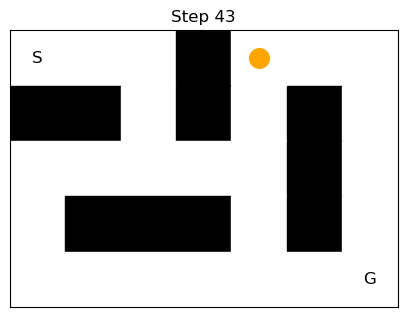

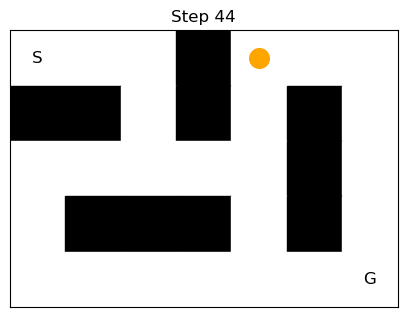

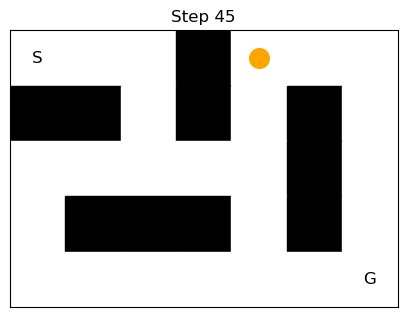

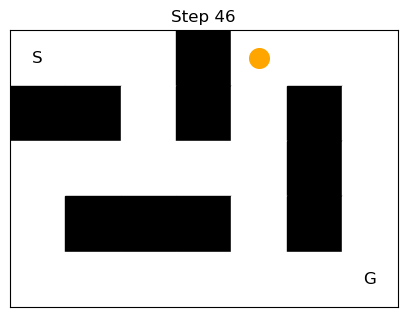

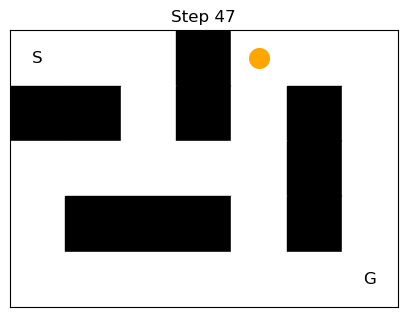

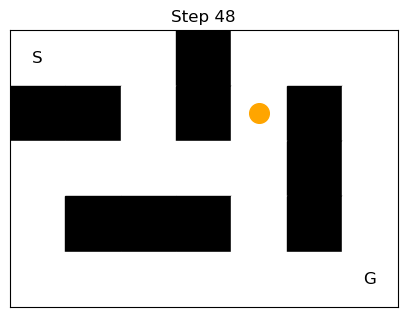

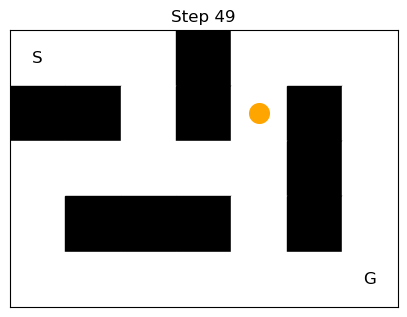

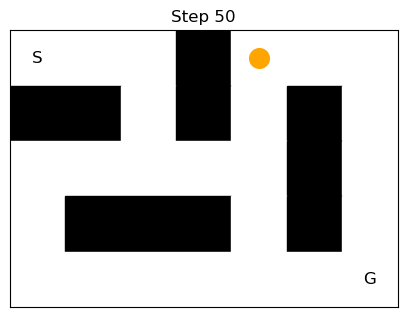

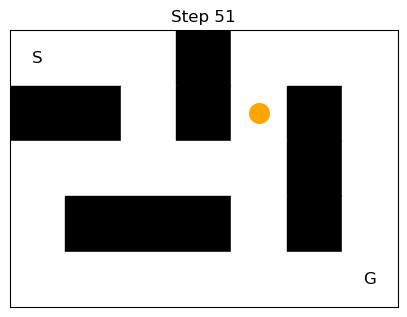

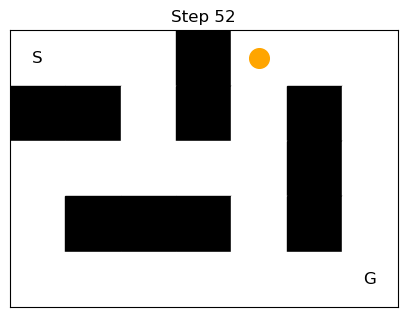

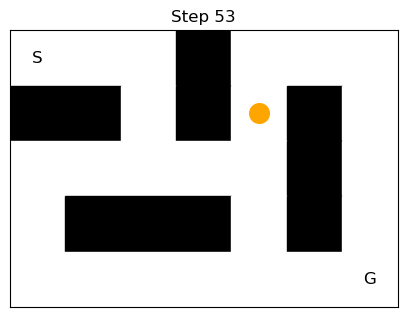

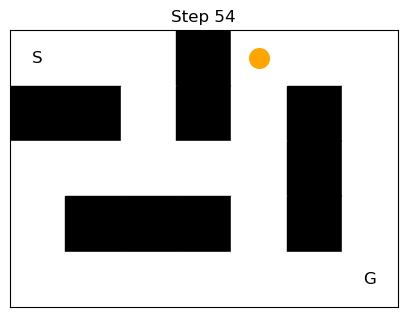

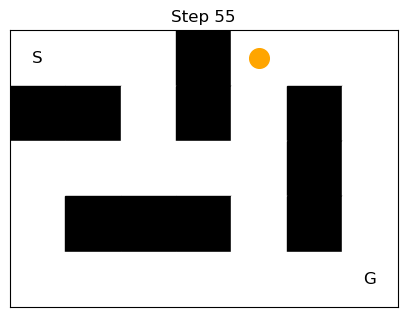

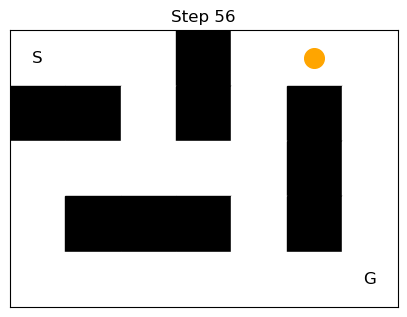

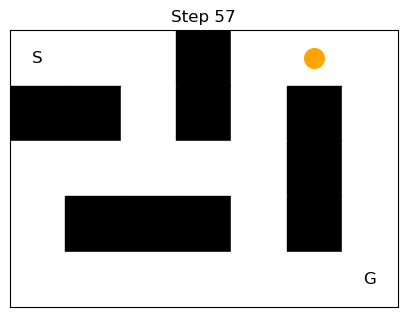

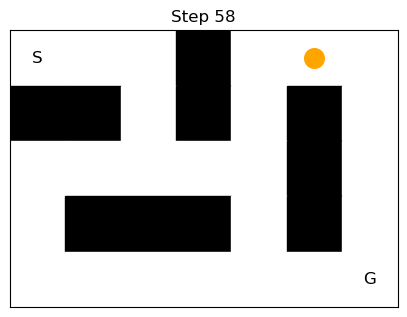

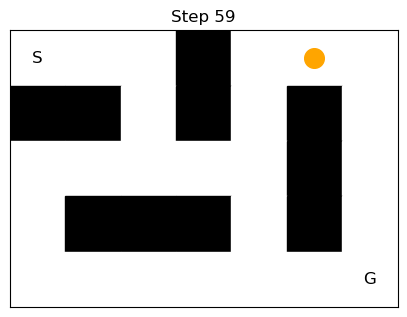

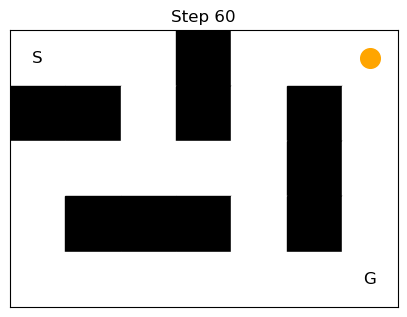

❌ Episode ended without reaching goal


In [14]:
maze = np.array([
    [2, 0, 0, 1, 0, 0, 0],
    [1, 1, 0, 1, 0, 1, 0],
    [0, 0, 0, 0, 0, 1, 0],
    [0, 1, 1, 1, 0, 1, 0],
    [0, 0, 0, 0, 0, 0, 3]
])

HEIGHT, WIDTH = maze.shape

env = MazeEnv(maze)
agent = Agent(epsilon=1.0)  # pure exploration
run_agent_episode(env, agent, max_steps=60, delay=0.25)


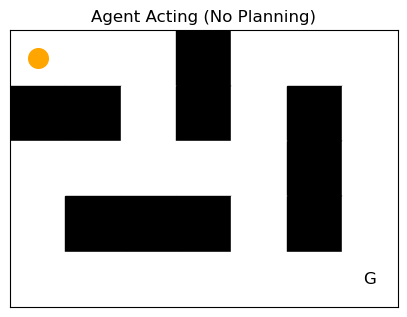

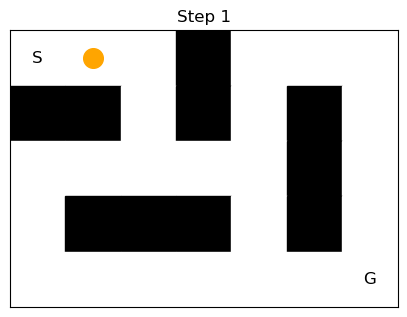

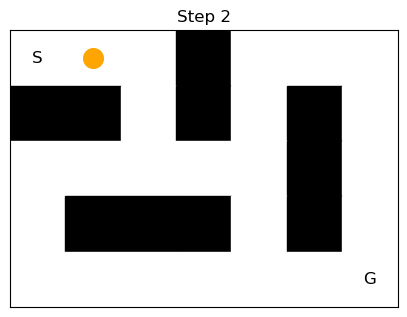

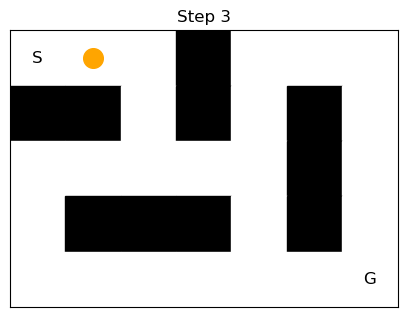

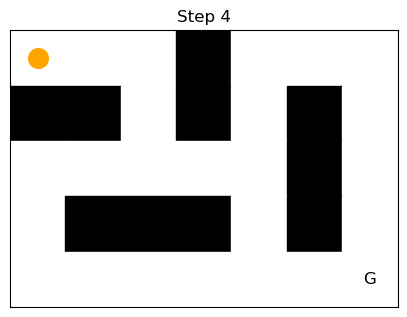

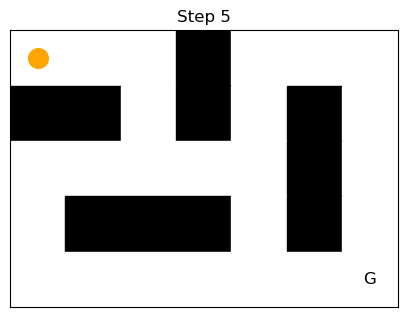

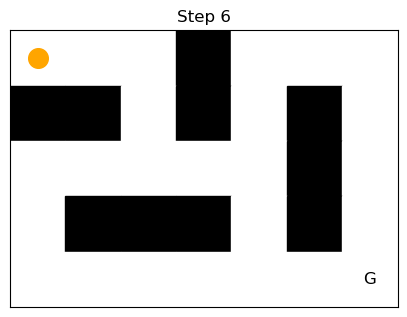

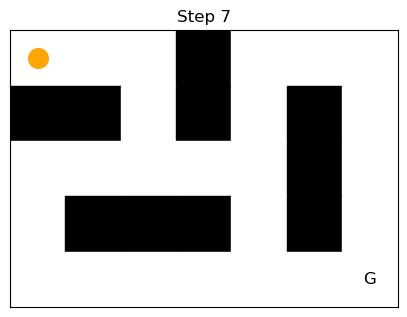

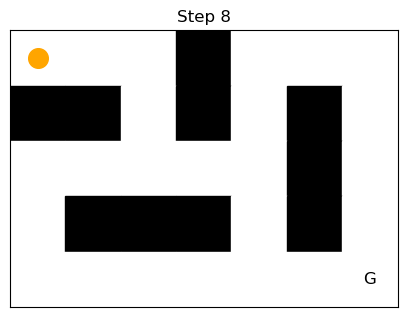

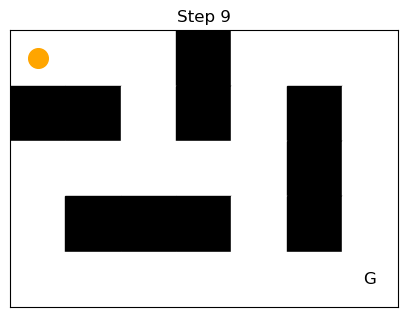

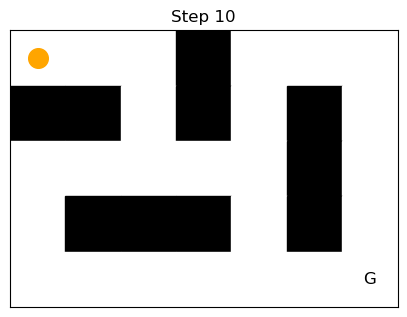

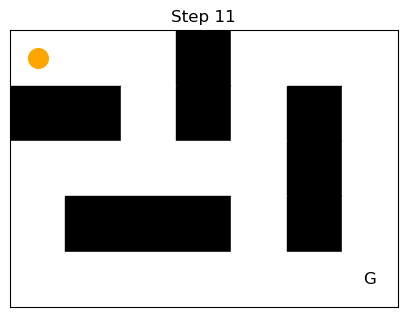

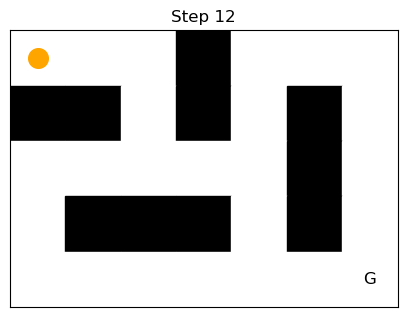

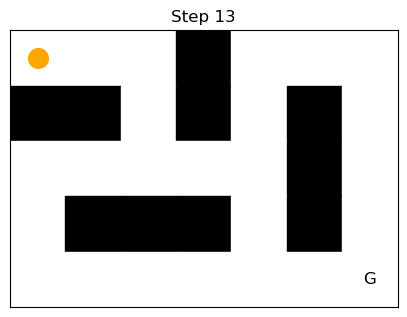

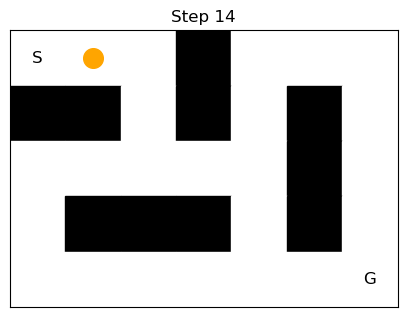

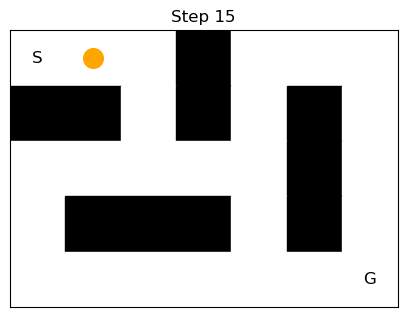

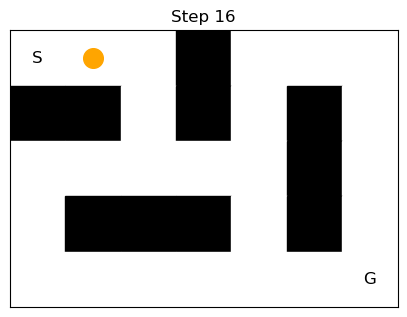

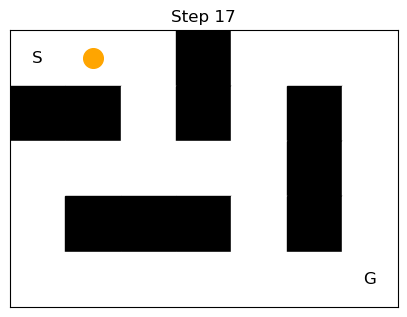

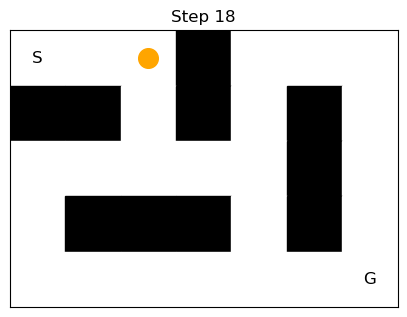

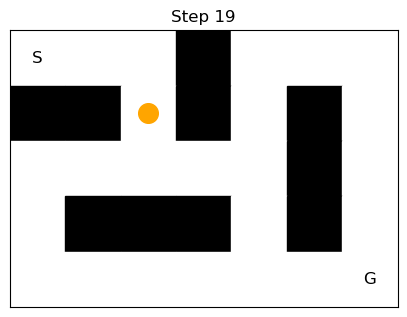

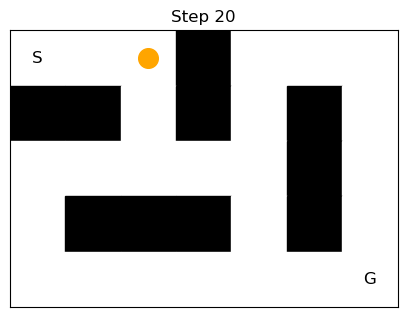

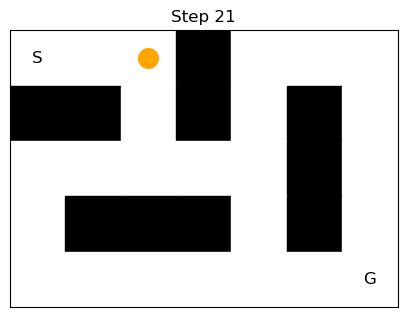

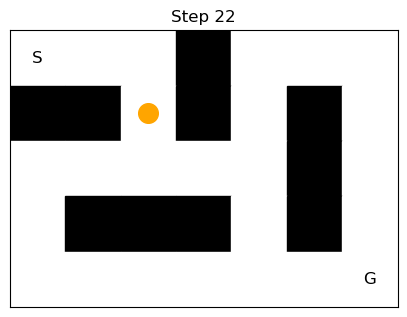

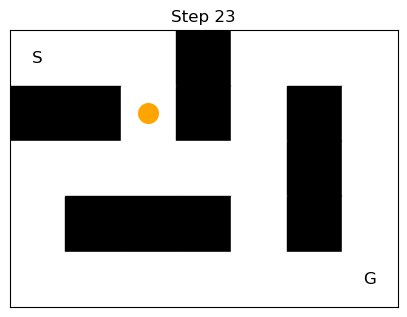

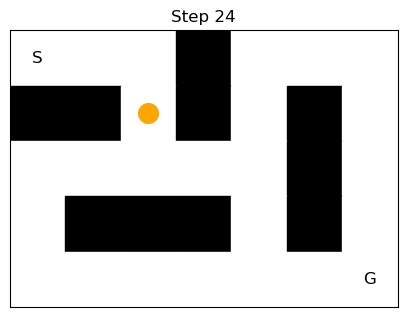

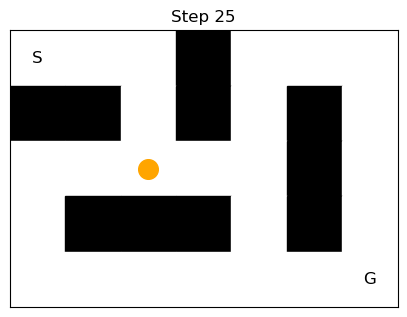

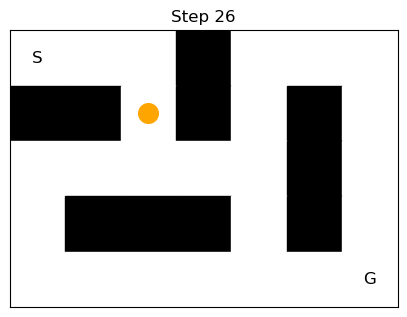

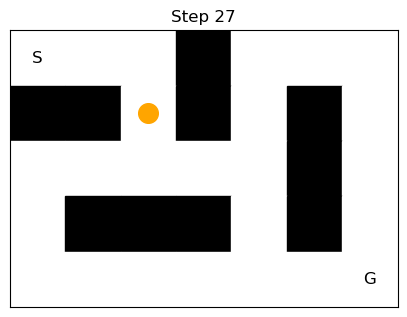

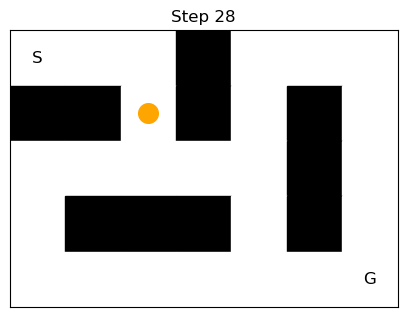

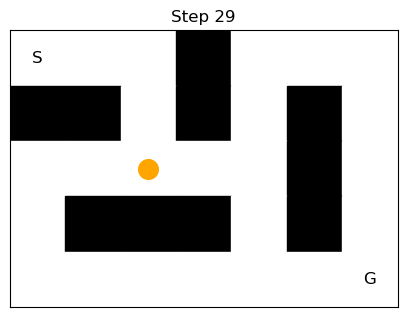

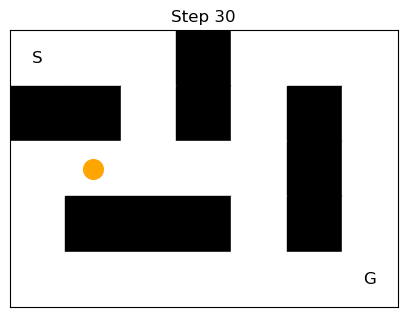

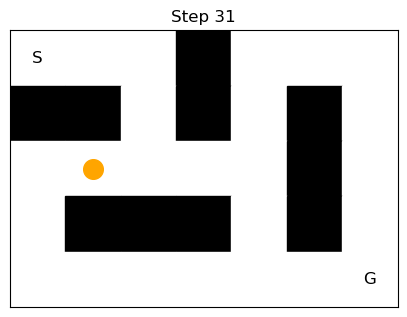

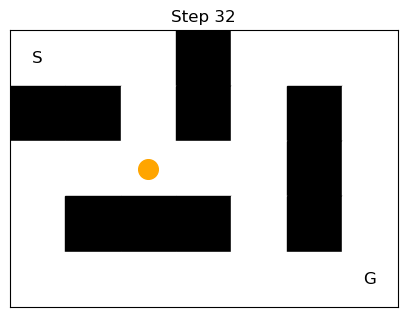

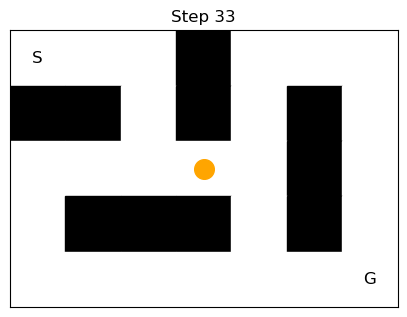

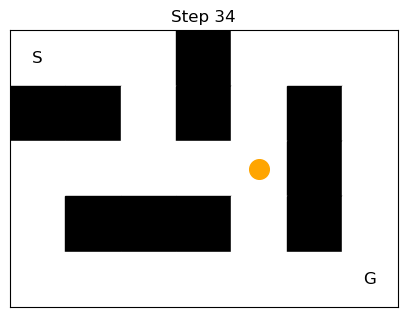

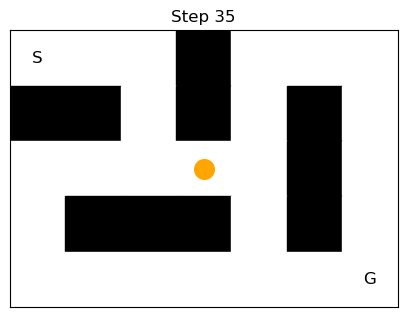

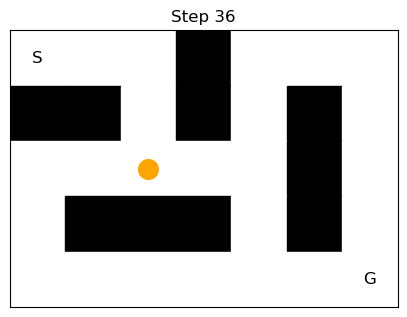

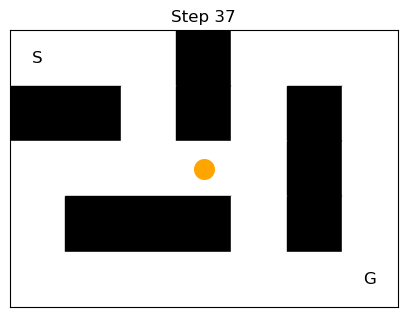

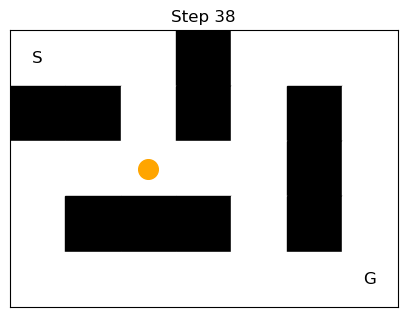

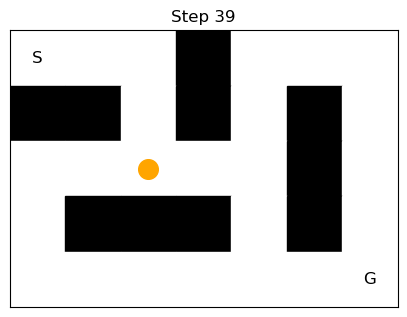

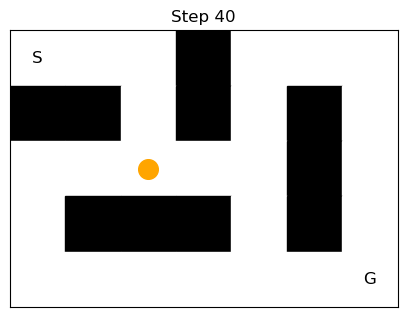

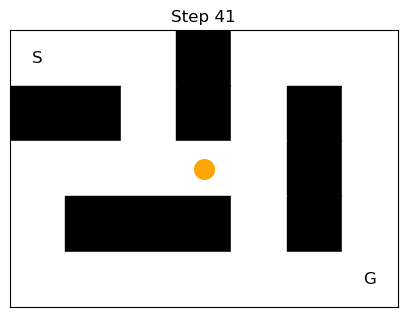

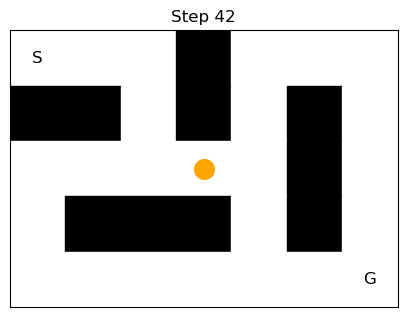

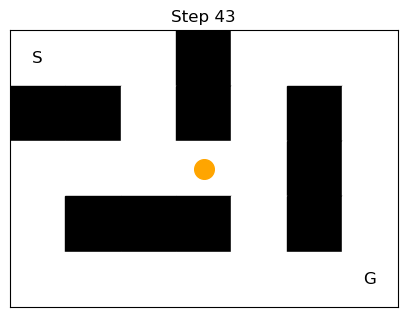

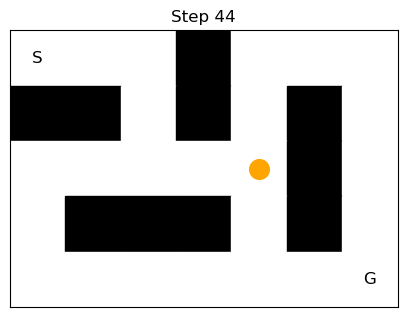

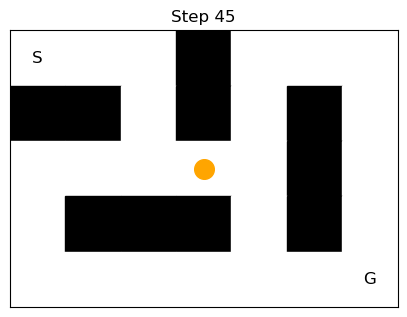

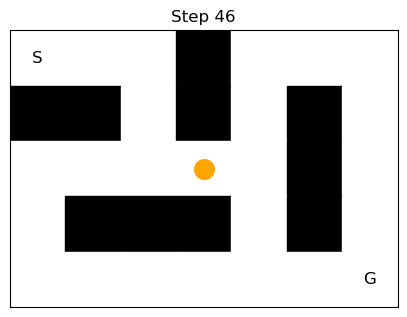

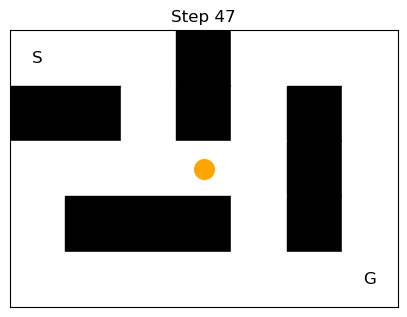

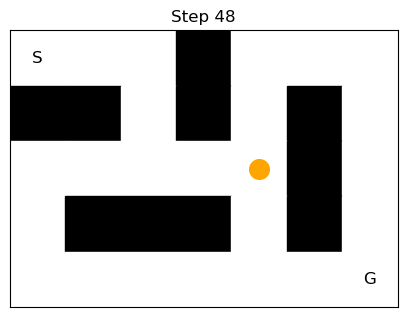

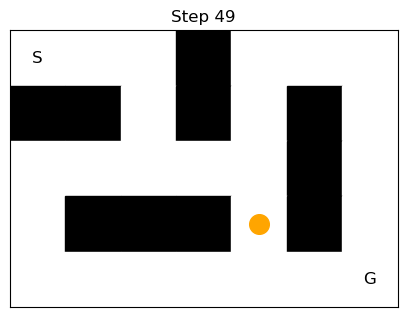

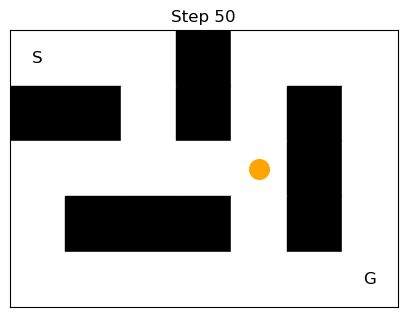

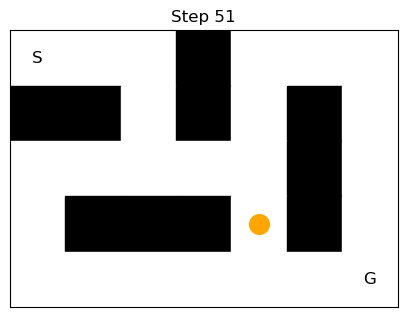

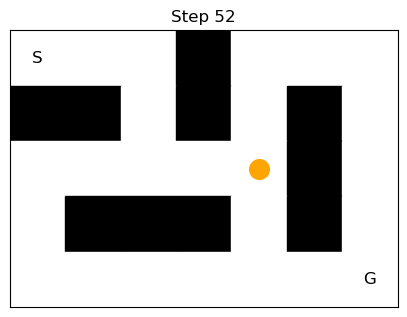

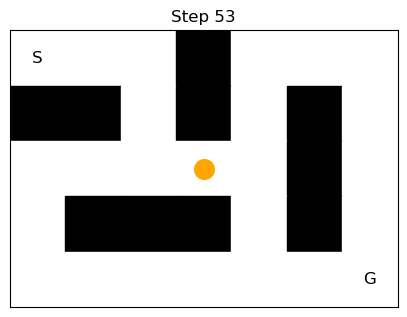

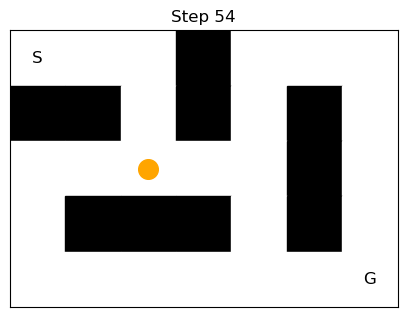

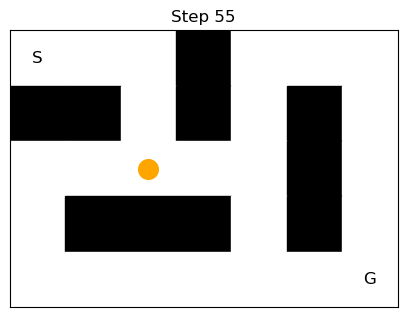

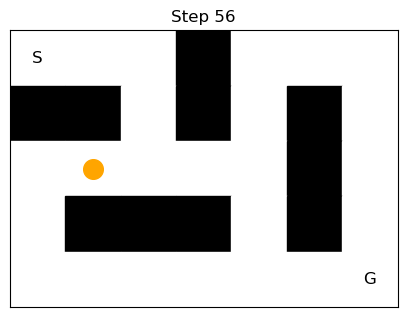

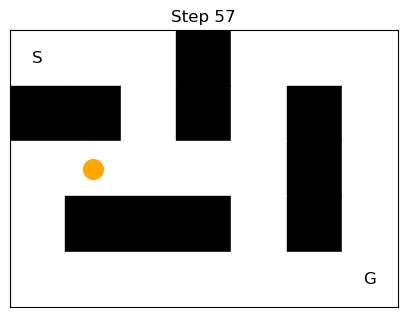

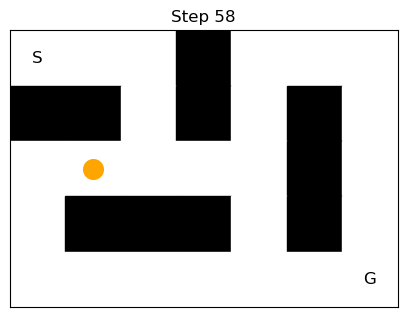

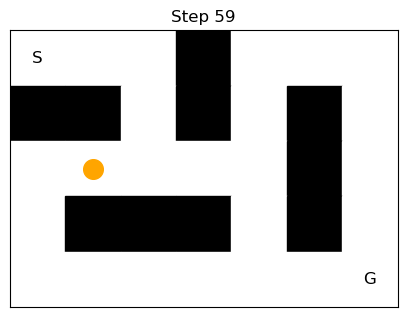

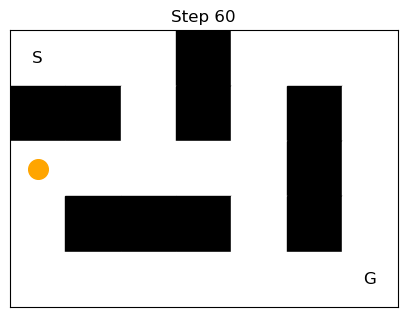

❌ Episode ended without reaching goal


In [16]:
agent = Agent(epsilon=0.0)
run_agent_episode(env, agent, max_steps=60, delay=0.25)